# Neural value-gradient solver

A bounded one-asset FBSNN experiment under the constant-parameter risk-neutral GBM model. A smooth value network is fitted with local discounted BSDE consistency and terminal payoff matching. Automatic differentiation supplies spot deltas and hence Brownian controls.

The notebook loads a saved run and evaluates it without retraining. Generate the default run from the repository root with:

```bash
python -m bsde_pricing train --run-dir scratch/runs/vanilla_fbsnn
```

Existing run directories are protected. The [methodology](../docs/methodology.md#first-value-gradient-training-experiment) defines the objective, streams, budgets and limits of this first experiment.

In [1]:
from pathlib import Path
import html
import json
import os
import platform

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from IPython.display import HTML, display

cwd = Path.cwd()
root = next((p for p in (cwd, cwd.parent) if (p / "bsde_pricing").is_dir()), None)
if root is None:
    raise RuntimeError("Open the deep-bsde-pricing repository folder before running the notebook.")
os.chdir(root)
from bsde_pricing.training import FBSNNSolver

%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

def table(headers, rows):
    heading = "".join(f"<th>{html.escape(str(v))}</th>" for v in headers)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(format(v, '.7g') if isinstance(v, (float, np.floating)) else str(v))}</td>"
        for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>"))

table(["Notebook runtime", "Version"], [("Python", platform.python_version()),
      ("NumPy", np.__version__), ("PyTorch", str(torch.__version__)),
      ("Matplotlib", matplotlib.__version__), ("System", platform.platform())])

Notebook runtime,Version
Python,3.12.16
NumPy,2.5.4
PyTorch,2.15.0
Matplotlib,3.11.2
System,macOS-27.0.1-arm64-arm-64bit


## 1. Saved experiment and financial scope

The network represents $V_\theta(t,S)$ and supplies $\Delta_\theta=\partial_S V_\theta$, with $Z_\theta=\sigma S\Delta_\theta$. Its physical-input normalisation is part of the graph. Training starts every path at the one specified spot and uses a fixed model and contract. It does not establish accuracy for different initial spots, model parameters or arbitrary states outside the sampled distribution.

The original recorded checkpoint is the last completed update. Current `train` runs save a validation-selected model as specified in section 8; the original version 1 file is retained for the results above. Monitoring paths are fixed, training paths are fresh at each update, and the post-training evaluation stream is separate. Monitoring did not select the original checkpoint. The targets are initial price error at most 0.25 currency units and delta error at most 0.02; a missed target remains visible.

In [2]:
run_dir = root / "scratch/runs/vanilla_fbsnn"
if not (run_dir / "model.pt").exists():
    raise FileNotFoundError("Create the saved run with: python -m bsde_pricing train --run-dir scratch/runs/vanilla_fbsnn")
report = json.loads((run_dir / "report.json").read_text())
solver = FBSNNSolver.load(run_dir / "model.pt")
history = report["history"]
config = report["config"]
initial = report["evaluation"]["initial"]
table(["Run setting", "Value"], [("Status", report["status"]),
      ("Completed updates", report["completed_updates"]), ("Time intervals", config["n_steps"]),
      ("Paths per update", config["batch_size"]), ("Hidden width", config["width"]),
      ("Parameters", sum(p.numel() for p in solver.network.parameters())),
      ("Seed", config["seed"]), ("Device / dtype", f"{report['device']} / {report['dtype']}"),
      ("Training seconds", report["training_seconds"]),
      ("Training runtime", f"Python {report['python']}, PyTorch {report['torch']}, {report['system']}")])
table(["Initial quantity", "Learned", "Analytical", "Signed error", "Target met"],
      [("Price", initial["price"], initial["reference_price"], initial["price_error"], report["targets_met"]["price"]),
       ("Delta", initial["delta"], initial["reference_delta"], initial["delta_error"], report["targets_met"]["delta"])])

Run setting,Value
Status,completed
Completed updates,3000
Time intervals,16
Paths per update,128
Hidden width,16
Parameters,337
Seed,2026
Device / dtype,cpu / torch.float64
Training seconds,6.205937
Training runtime,"Python 3.12.16, PyTorch 2.15.0, macOS-27.0.1-arm64-arm-64bit"


Initial quantity,Learned,Analytical,Signed error,Target met
Price,9.562298,9.413403,0.1488942,True
Delta,0.5160792,0.5987063,-0.08262714,False


## 2. Objective during optimisation

The dimensionless loss is the path-average sum of squared discounted local residuals divided by strike squared, plus the separately normalised terminal error. The training curve averages pre-update losses over each logging window; monitoring losses evaluate the updated model on one fixed path sample.

The dashed analytical local loss uses the same monitoring paths. It is a discretisation comparison, not a lower bound on the discrete objective. A network can trade local residuals against terminal fit, and lower loss does not by itself establish more accurate price or delta.

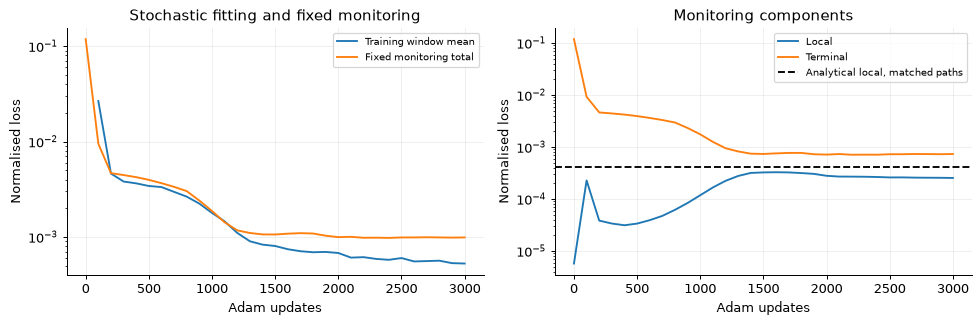

In [3]:
steps = np.array([h["step"] for h in history])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
logged_training = [h for h in history if h["training_loss_window_mean"] is not None]
axes[0].semilogy([h["step"] for h in logged_training],
                 [h["training_loss_window_mean"] for h in logged_training], label="Training window mean")
axes[0].semilogy(steps, [h["validation_total"] for h in history], label="Fixed monitoring total")
axes[1].semilogy(steps, [h["validation_local"] for h in history], label="Local")
axes[1].semilogy(steps, [h["validation_terminal"] for h in history], label="Terminal")
axes[1].axhline(report["validation_analytical_local_loss"], linestyle="--", color="black",
                label="Analytical local, matched paths")
for ax in axes:
    ax.set_xlabel("Adam updates")
    ax.set_ylabel("Normalised loss")
    ax.legend(fontsize=8)
axes[0].set_title("Stochastic fitting and fixed monitoring")
axes[1].set_title("Monitoring components")
fig.tight_layout()
plt.show()

## 3. Initial price and delta errors

These errors compare the deterministic network output and its input derivative at $(0,S_0)$ with Black-Scholes. They have no Monte Carlo standard error for a fixed trained model. Seed variability is a separate experiment. Signed symlog axes show the full trajectory, including the untrained model, while keeping the target bands visible.

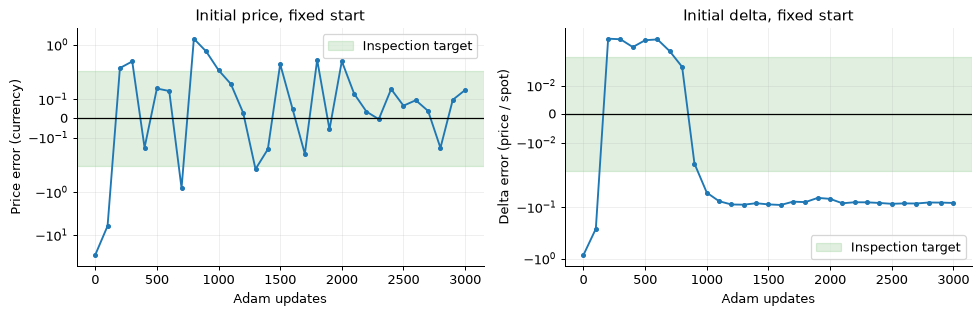

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, field, target, label in zip(axes, ("price_error", "delta_error"), (0.25, 0.02),
                                   ("Price error (currency)", "Delta error (price / spot)")):
    ax.plot(steps, [h[field] for h in history], "o-", markersize=3)
    ax.axhline(0, color="black", linewidth=1)
    ax.axhspan(-target, target, color="green", alpha=0.12, label="Inspection target")
    ax.set_yscale("symlog", linthresh=target)
    ax.set_xlabel("Adam updates")
    ax.set_ylabel(label)
    ax.legend()
axes[0].set_title("Initial price, fixed start")
axes[1].set_title("Initial delta, fixed start")
fig.tight_layout()
plt.show()

## 4. Fresh-path evaluation

The saved report contains the post-training evaluation using SeedSequence child 2. The additional sample below uses an explicit new seed and branch 3 for descriptive plots; it is not used for fitting or checkpoint selection. Errors are measured at pre-expiry grid points on the fixed-start path distribution. Terminal value error is reported separately, and terminal deltas are excluded.

Standard errors for mean signed errors use independent path averages, accounting for dependence across time within a path. They describe evaluation sampling uncertainty for this fixed model, not uncertainty from optimisation or the training seed.

In [5]:
plot_paths = 512
plot_seed = 2027
evaluation = solver.evaluate(n_paths=plot_paths, seed=plot_seed)
summary = evaluation.summary
table(["Measure", "Saved evaluation", "Fresh plotting sample"],
      [("Paths", report["evaluation"]["n_paths"], summary["n_paths"]),
       ("Pre-expiry price RMSE", report["evaluation"]["price_rmse_before_expiry"], summary["price_rmse_before_expiry"]),
       ("Pre-expiry delta RMSE", report["evaluation"]["delta_rmse_before_expiry"], summary["delta_rmse_before_expiry"]),
       ("Terminal payoff RMSE", report["evaluation"]["terminal_payoff_rmse"], summary["terminal_payoff_rmse"]),
       ("Local loss", report["evaluation"]["local_loss"], summary["local_loss"]),
       ("Analytical local loss, matched paths", report["evaluation"]["analytical_local_loss"], summary["analytical_local_loss"])])
table(["Fresh mean signed error", "Estimate", "Path-level SE"],
      [("Price", summary["mean_price_error"], summary["mean_price_error_se"]),
       ("Delta", summary["mean_delta_error"], summary["mean_delta_error_se"])])

Measure,Saved evaluation,Fresh plotting sample
Paths,2048,512
Pre-expiry price RMSE,0.9222957,0.9037401
Pre-expiry delta RMSE,0.1162418,0.1169896
Terminal payoff RMSE,1.755475,1.720026
Local loss,0.0002490521,0.0002474045
"Analytical local loss, matched paths",0.000395916,0.0004216958


Fresh mean signed error,Estimate,Path-level SE
Price,0.1086616,0.02537321
Delta,-0.008816053,0.003427173


## 5. Representative trajectories

The first three generated paths are retained without selection by prediction quality. Solid value curves show the learned model; dashed curves show the analytical reference on the same states.

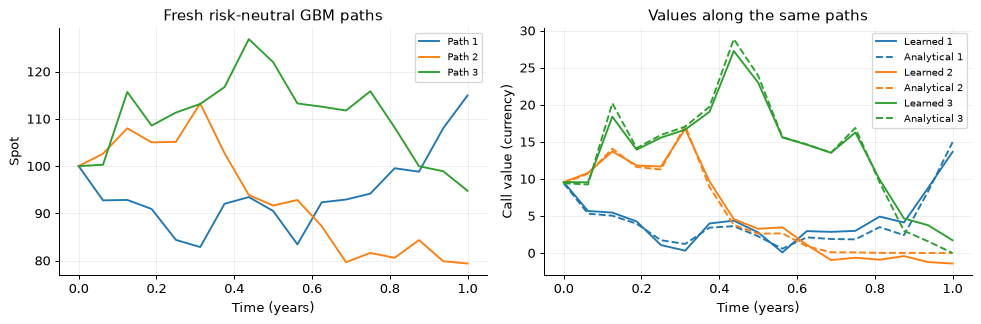

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
for k in range(3):
    line, = axes[0].plot(evaluation.times, evaluation.spots[k], label=f"Path {k+1}")
    axes[1].plot(evaluation.times, evaluation.values[k], color=line.get_color(), label=f"Learned {k+1}")
    axes[1].plot(evaluation.times, evaluation.reference_values[k], "--", color=line.get_color(), label=f"Analytical {k+1}")
axes[0].set_ylabel("Spot")
axes[1].set_ylabel("Call value (currency)")
for ax in axes:
    ax.set_xlabel("Time (years)")
    ax.legend(fontsize=8)
axes[0].set_title("Fresh risk-neutral GBM paths")
axes[1].set_title("Values along the same paths")
fig.tight_layout()
plt.show()

## 6. Conditional state slices

Each column uses a selected interior time on the existing grid. Curves connect sorted sampled states; no new initial-spot training problem is introduced. The displayed ranges reflect the fresh path sample. The comparison can reveal slope errors even where prices appear close.

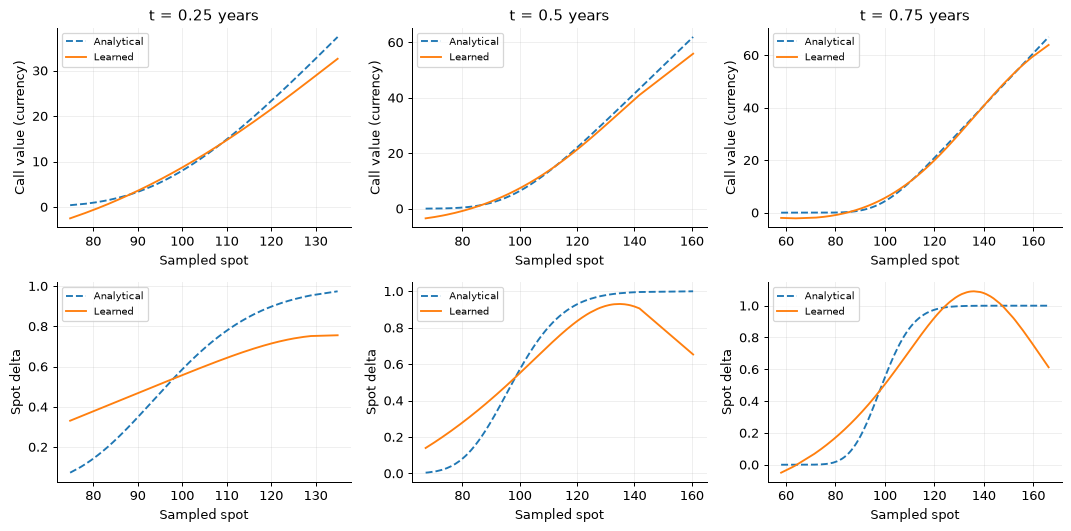

In [7]:
indices = sorted(set(max(1, min(config["n_steps"]-1, round(config["n_steps"]*fraction)))
                     for fraction in (0.25, 0.5, 0.75)))
fig, axes = plt.subplots(2, len(indices), figsize=(4*len(indices), 6), squeeze=False)
for column, index in enumerate(indices):
    order = np.argsort(evaluation.spots[:, index])
    sample_spots = evaluation.spots[order, index]
    axes[0, column].plot(sample_spots, evaluation.reference_values[order, index], "--", label="Analytical")
    axes[0, column].plot(sample_spots, evaluation.values[order, index], label="Learned")
    axes[1, column].plot(sample_spots, evaluation.reference_deltas[order, index], "--", label="Analytical")
    axes[1, column].plot(sample_spots, evaluation.deltas[order, index], label="Learned")
    axes[0, column].set_title(f"t = {evaluation.times[index]:.3g} years")
    axes[0, column].set_ylabel("Call value (currency)")
    axes[1, column].set_ylabel("Spot delta")
    for row in range(2):
        axes[row, column].set_xlabel("Sampled spot")
        axes[row, column].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Terminal payoff fit

The call payoff has a kink, while the tanh value network is smooth. The fit near strike and in sampled tails is visible below. This experiment does not yet separate network approximation, optimisation and grid bias; the observed errors are retained before any controlled follow-up experiment.

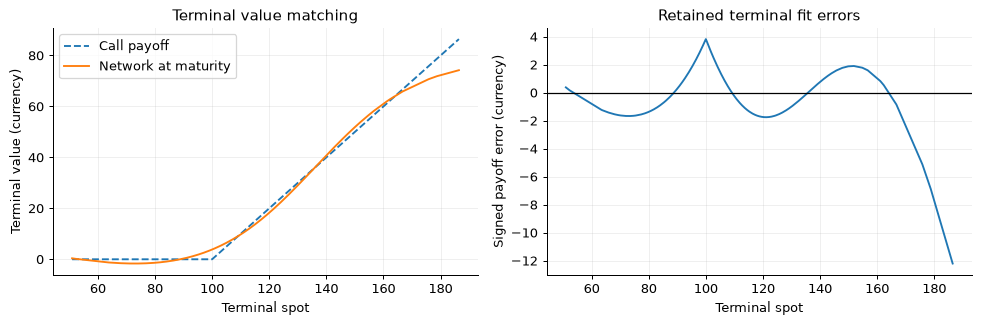

In [8]:
order = np.argsort(evaluation.spots[:, -1])
terminal_spots = evaluation.spots[order, -1]
terminal_errors = evaluation.values[order, -1]-evaluation.reference_values[order, -1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].plot(terminal_spots, evaluation.reference_values[order, -1], "--", label="Call payoff")
axes[0].plot(terminal_spots, evaluation.values[order, -1], label="Network at maturity")
axes[0].set_ylabel("Terminal value (currency)")
axes[0].legend()
axes[1].plot(terminal_spots, terminal_errors)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_ylabel("Signed payoff error (currency)")
for ax in axes:
    ax.set_xlabel("Terminal spot")
axes[0].set_title("Terminal value matching")
axes[1].set_title("Retained terminal fit errors")
fig.tight_layout()
plt.show()

## Interpretation

- Training and monitoring losses describe the discrete objective. Price and delta errors assess different quantities against an independent reference.
- The last completed update is retained even if an earlier monitoring point had a smaller error. Inspection targets are reported without extending the run until they pass.
- Fresh-path metrics are conditional on this model, contract, fixed start and time grid. They do not establish performance over all spots or model parameters.
- A single training seed does not measure optimisation variability. Checkpoint selection, seed comparisons and exact optimiser continuation are assessed in the sections below.

## 8. Seed variation and terminal-loss weighting

The first experiment remains above, including its missed delta target. The comparison below holds its architecture, path budget, time grid and learning-rate schedule fixed. Seeds **2026, 2027 and 2028** each run with terminal-loss weights **1 and 5**. Weight 5 is a single declared perturbation, not the outcome of a search. Each pair starts from identical network weights and uses identical training, validation and evaluation paths.

For each run, checkpoint selection minimises the **weighted validation objective** over the scheduled checks. No analytical price, delta or held-out metric enters selection. Both the selected checkpoint and the final update are evaluated on the same fresh paths. Early stopping is disabled in this fixed-budget comparison. Three seeds describe variability; they do not establish a reliable tail probability or a universal preferred weight.

Generate the study once from the repository root. Existing directories are protected:

```bash
python -m bsde_pricing training-study --run-dir scratch/runs/reproducibility
```

The notebook loads these files without training. Weighted total losses across different weights have different meanings, so the comparison uses physical errors and the common unweighted loss components.

The retained first-experiment outputs were recorded on the MacBook. The appended study table records the runtime for its results. Running all cells locally refreshes both sets from their saved files.

In [9]:
study_dir = root / "scratch/runs/reproducibility"
study = json.loads((study_dir / "study.json").read_text())
rows = study["runs"]
usable = [r for r in rows if r["status"] in ("completed", "time_budget_reached")]
table(["Study status", "Seeds", "Weights", "Failed runs", "Wall seconds"], [[
    study["status"], study["seeds"], study["terminal_weights"],
    sum(r["status"] == "failed" for r in rows), f'{study["wall_seconds"]:.3f}']])
table(["Seed", "Weight", "Status", "Updates", "Selected step", "Fit seconds", "Evaluation seconds"], [
    [r["seed"], r["terminal_weight"], r["status"], r.get("completed_updates", ""),
     r.get("selected_step", ""), f'{r.get("training_seconds", 0):.3f}' if "training_seconds" in r else "",
     f'{r.get("evaluation_seconds", 0):.3f}' if "evaluation_seconds" in r else r.get("error", "")]
    for r in rows])
reports = {r["directory"]: json.loads((study_dir / r["directory"] / "report.json").read_text()) for r in usable}
table(["Seed", "Weight", "Python", "NumPy", "PyTorch", "System"], [
    [r["seed"], r["terminal_weight"], reports[r["directory"]]["python"], reports[r["directory"]]["numpy"],
     reports[r["directory"]]["torch"], reports[r["directory"]]["system"]] for r in usable])

Study status,Seeds,Weights,Failed runs,Wall seconds
completed,"[2026, 2027, 2028]","[1, 5]",0,99.249


Seed,Weight,Status,Updates,Selected step,Fit seconds,Evaluation seconds
2026,1,completed,3000,2400,15.327,0.475
2026,5,completed,3000,1400,14.723,0.379
2027,1,completed,3000,3000,14.167,0.411
2027,5,completed,3000,3000,16.207,0.784
2028,1,completed,3000,3000,15.536,0.417
2028,5,completed,3000,2900,18.266,0.353


Seed,Weight,Python,NumPy,PyTorch,System
2026,1,3.12.14,2.3.5,2.15.0+cpu,Linux-6.18.57-x86_64-with-glibc2.39
2026,5,3.12.14,2.3.5,2.15.0+cpu,Linux-6.18.57-x86_64-with-glibc2.39
2027,1,3.12.14,2.3.5,2.15.0+cpu,Linux-6.18.57-x86_64-with-glibc2.39
2027,5,3.12.14,2.3.5,2.15.0+cpu,Linux-6.18.57-x86_64-with-glibc2.39
2028,1,3.12.14,2.3.5,2.15.0+cpu,Linux-6.18.57-x86_64-with-glibc2.39
2028,5,3.12.14,2.3.5,2.15.0+cpu,Linux-6.18.57-x86_64-with-glibc2.39


## 9. Initial price and delta across seeds

The shaded bands retain the original inspection targets: 0.25 price units and 0.02 delta. Checkpoint selection is based on the BSDE validation objective and need not minimise either error. The final-update results for seed 2026 and weight 1 provide the direct numerical check against the first experiment.

Seed,Weight,Checkpoint,Price error,Delta error,Terminal RMSE,Unweighted loss
2026,1,selected,+0.153759,-0.082716,1.837602,0.0005832
2026,1,last,+0.148894,-0.082627,1.755475,0.0005393
2026,5,selected,-0.196764,-0.109352,2.017263,0.0008090
2026,5,last,+0.231194,-0.086123,1.622910,0.0006618
2027,1,selected,+0.156187,-0.027648,1.252561,0.0003841
2027,1,last,+0.156187,-0.027648,1.252561,0.0003841
2027,5,selected,+0.258338,-0.058811,1.211835,0.0004215
2027,5,last,+0.258338,-0.058811,1.211835,0.0004215
2028,1,selected,-0.154162,+0.004470,1.459337,0.0004430
2028,1,last,-0.154162,+0.004470,1.459337,0.0004430


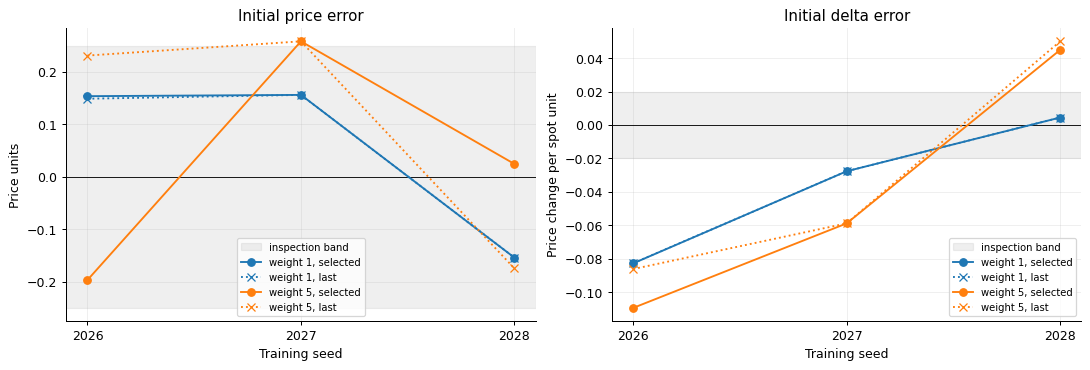

In [10]:
table(["Seed", "Weight", "Checkpoint", "Price error", "Delta error", "Terminal RMSE", "Unweighted loss"], [
    [r["seed"], r["terminal_weight"], checkpoint, f'{r[checkpoint]["price_error"]:+.6f}',
     f'{r[checkpoint]["delta_error"]:+.6f}', f'{r[checkpoint]["terminal_payoff_rmse"]:.6f}',
     f'{r[checkpoint]["unweighted_total_loss"]:.7f}']
    for r in usable for checkpoint in ("selected", "last")])
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, tolerance, title in zip(axes, ("price_error", "delta_error"), (0.25, 0.02),
                                       ("Initial price error", "Initial delta error")):
    ax.axhspan(-tolerance, tolerance, color="grey", alpha=0.12, label="inspection band")
    ax.axhline(0, color="black", linewidth=0.7)
    for weight, color in zip(study["terminal_weights"], ("tab:blue", "tab:orange")):
        group = [r for r in usable if r["terminal_weight"] == weight]
        for checkpoint, marker, linestyle in (("selected", "o", "-"), ("last", "x", ":")):
            ax.plot([r["seed"] for r in group], [r[checkpoint][metric] for r in group],
                    marker=marker, linestyle=linestyle, color=color, label=f"weight {weight}, {checkpoint}")
    ax.set(title=title, xlabel="Training seed", xticks=study["seeds"])
    ax.legend(fontsize=8)
axes[0].set_ylabel("Price units")
axes[1].set_ylabel("Price change per spot unit")
plt.show()

## 10. Fresh-path errors and loss components

Terminal fit, price fit and delta fit answer different questions. Sample standard deviations below describe variation between three independently seeded runs. The two weights share streams within each seed. They are not six independent estimates of one configuration. The local and terminal losses are dimensionless; terminal RMSE is in price units.

Weight,Checkpoint,Complete / usable,Price error mean (sd),Delta error mean (sd),Terminal RMSE mean (sd),Fit seconds mean (sd)
1,selected,3 / 3,0.05193 (0.17848),-0.03530 (0.04409),1.51650 (0.29668),15.00980 (0.73748)
1,last,3 / 3,0.05031 (0.17711),-0.03527 (0.04405),1.48912 (0.25278),15.00980 (0.73748)
5,selected,3 / 3,0.02869 (0.22758),-0.04109 (0.07863),1.52509 (0.43149),16.39879 (1.77933)
5,last,3 / 3,0.10493 (0.24259),-0.03164 (0.07202),1.39306 (0.20981),16.39879 (1.77933)


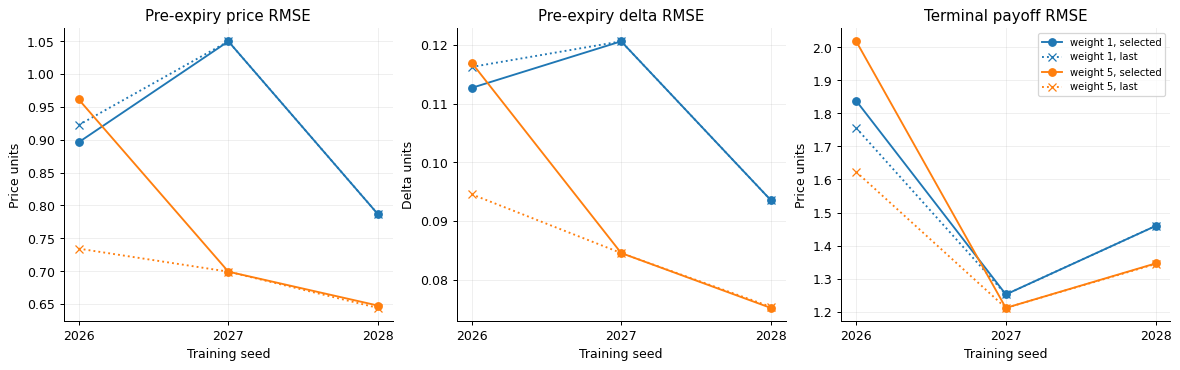

In [11]:
table(["Weight", "Checkpoint", "Complete / usable", "Price error mean (sd)", "Delta error mean (sd)",
       "Terminal RMSE mean (sd)", "Fit seconds mean (sd)"], [
    [s["terminal_weight"], s["checkpoint"], f'{s["completed_runs"]} / {s["usable_runs"]}',
     *[f'{s[k]["mean"]:.5f} ({s[k]["sample_std"]:.5f})' if s[k]["sample_std"] is not None
       else str(s[k]["mean"]) for k in ("price_error", "delta_error", "terminal_payoff_rmse", "training_seconds")]]
    for s in study["summary"]])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for ax, metric, title in zip(axes,
        ("price_rmse_before_expiry", "delta_rmse_before_expiry", "terminal_payoff_rmse"),
        ("Pre-expiry price RMSE", "Pre-expiry delta RMSE", "Terminal payoff RMSE")):
    for weight, color in zip(study["terminal_weights"], ("tab:blue", "tab:orange")):
        group = [r for r in usable if r["terminal_weight"] == weight]
        for checkpoint, marker, linestyle in (("selected", "o", "-"), ("last", "x", ":")):
            ax.plot([r["seed"] for r in group], [r[checkpoint][metric] for r in group],
                    marker=marker, linestyle=linestyle, color=color, label=f"weight {weight}, {checkpoint}")
    ax.set(title=title, xlabel="Training seed", xticks=study["seeds"])
axes[0].set_ylabel("Price units")
axes[1].set_ylabel("Delta units")
axes[2].set_ylabel("Price units")
axes[2].legend(fontsize=8)
plt.show()

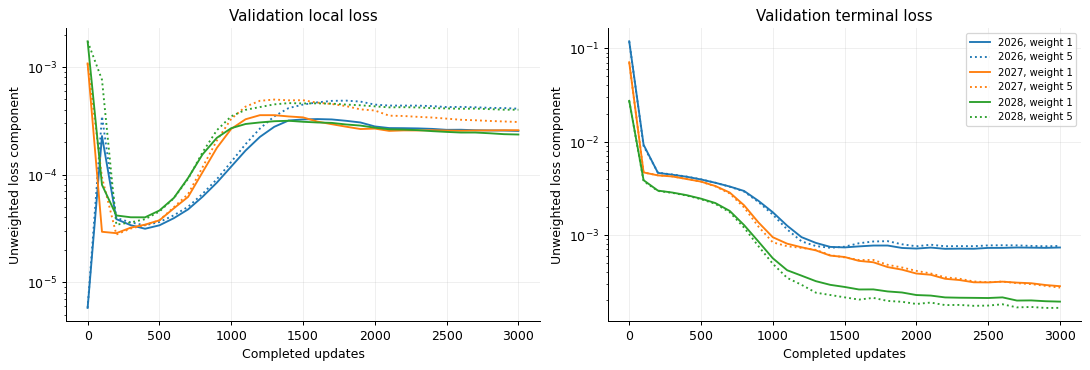

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for r in usable:
    history = reports[r["directory"]]["history"]
    color = {2026: "tab:blue", 2027: "tab:orange", 2028: "tab:green"}[r["seed"]]
    style = "-" if r["terminal_weight"] == 1 else ":"
    for ax, key, title in zip(axes, ("validation_local", "validation_terminal"),
                              ("Validation local loss", "Validation terminal loss")):
        ax.semilogy([h["step"] for h in history], [h[key] for h in history],
                    color=color, linestyle=style, label=f'{r["seed"]}, weight {r["terminal_weight"]}')
        ax.set(title=title, xlabel="Completed updates", ylabel="Unweighted loss component")
axes[1].legend(fontsize=8)
plt.show()

## 11. Exact continuation and saved-model evaluation

The continuation check pauses after update 37 of an 80-update verification run. This falls between the logging checks and precedes the learning-rate change. It restores the latest model, Adam moments and step counter, training RNG, fixed validation paths, best-checkpoint state, stopping counter and unfinished loss window. Numerical states and held-out evaluation must match the uninterrupted run exactly on the same runtime. Elapsed times are excluded.

`model.pt` contains the selected inference weights. `resume.pt` contains the latest training state, which can differ from those weights. The version 1 checkpoint from the first experiment remains readable for inference.

In [13]:
check = study["resume_check"]
table(["Continuation check", "Passed"], list(check["checks"].items()))
if not check["passed"]:
    raise RuntimeError("Continuation check failed; inspect the retained checkpoint files.")
loaded_rows = []
for r in usable:
    model = FBSNNSolver.load(study_dir / r["directory"] / "model.pt")
    point = model.initial_value()
    saved = r["selected"]
    discrepancy = max(abs(point[k]-saved[k]) for k in ("price", "delta"))
    if discrepancy > 1e-12:
        raise ArithmeticError("Loaded model disagrees with its saved evaluation.")
    loaded_rows.append([r["seed"], r["terminal_weight"], f'{point["price"]:.8f}',
                        f'{point["delta"]:.8f}', f"{discrepancy:.2g}"])
table(["Seed", "Weight", "Reloaded price", "Reloaded delta", "Max saved-point discrepancy"], loaded_rows)

Continuation check,Passed
current_weights,True
optimizer_state,True
train_rng_state,True
evaluation_rng_state,True
torch_rng_state,True
validation,True
best_state,True
best_step,True
checks_without_improvement,True
window,True


Seed,Weight,Reloaded price,Reloaded delta,Max saved-point discrepancy
2026,1,9.56716227,0.51599016,0
2026,5,9.21663969,0.48935475,0
2027,1,9.56959071,0.57105878,0
2027,5,9.67174100,0.53989506,0
2028,1,9.25924119,0.60317634,0
2028,5,9.43788557,0.64359073,0


Validation selection can reduce its own objective without improving the initial delta. Increasing terminal weight changes the optimisation balance but does not remove the finite time grid, finite network or payoff kink. Conclusions should retain both successful and missed inspection targets, runtime, seed dispersion and failed or time-limited runs. These six runs do not settle which of those mechanisms dominates the remaining error.